<a href="https://colab.research.google.com/github/TokaElsaayed/Deep-project/blob/person1-baseline-cnn/baseline_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!git clone https://github.com/TokaElsaayed/Deep-project.git
%cd Deep-project
!ls -la



Cloning into 'Deep-project'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 49 (delta 3), reused 44 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 7.48 MiB | 7.86 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/Deep-project
total 52
drwxr-xr-x 8 root root 4096 Oct 27 15:10 .
drwxr-xr-x 1 root root 4096 Oct 27 15:10 ..
drwxr-xr-x 2 root root 4096 Oct 27 15:10 configs
drwxr-xr-x 8 root root 4096 Oct 27 15:10 .git
-rw-r--r-- 1 root root  151 Oct 27 15:10 .gitignore
drwxr-xr-x 2 root root 4096 Oct 27 15:10 notebooks
drwxr-xr-x 3 root root 4096 Oct 27 15:10 outputs
-rw-r--r-- 1 root root 8858 Oct 27 15:10 README.md
-rw-r--r-- 1 root root   87 Oct 27 15:10 requirements.txt
drwxr-xr-x 3 root root 4096 Oct 27 15:10 src
drwxr-xr-x 2 root root 4096 Oct 27 15:10 tests


In [ ]:

!cat README.md
!find src configs notebooks tests -maxdepth 3 -type f


# From Pixels to Language — Task 1.1 (EDA)

This repository's first milestone analyzes the CUB bird images/captions, creates a leakage-aware train/validation/test split, and prepares image transforms for classification. Paths, dataset IDs, split seed, pHash threshold, preprocessing sizes, and augmentation settings are in `configs/eda.yaml`.

## Rebuild the EDA outputs

Run these commands from the repository root. The first command downloads/loads the configured Hugging Face datasets; the first run needs network access. The EDA command rebuilds the raw image/caption reports, plots, cleaned captions, and split. If `outputs/eda/confirmed_perceptual_removals.csv` is present, it also excludes those previously reviewed training copies (never test records).

```powershell
python -m venv .venv
.venv\Scripts\python.exe -m pip install -r requirements.txt
.venv\Scripts\python.exe -m src.data.eda --config configs/eda.yaml
.venv\Scripts\python.exe -m src.data.transforms --config configs/eda.yaml
.v

In [ ]:
!find src configs notebooks tests -maxdepth 3 -type f


src/cli.py
src/data/eda.py
src/data/__init__.py
src/data/clean_phase2.py
src/data/transforms.py
src/data/near_duplicates.py
configs/eda.yaml
notebooks/01_load_data.ipynb
tests/test_transforms.py
tests/test_clean_phase2.py


In [ ]:

!cat src/data/transforms.py


"""Config-driven image preprocessing and train-only augmentation utilities."""

from __future__ import annotations

import argparse
import math
import random
from pathlib import Path
from typing import Any, Iterable

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageEnhance

from src.data.eda import _image_object, load_cub_datasets


def _resize_short_side(image: Image.Image, short_side: int) -> Image.Image:
    width, height = image.size
    if width <= height:
        new_width = short_side
        new_height = int(short_side * height / width)
    else:
        new_height = short_side
        new_width = int(short_side * width / height)
    return image.resize((new_width, new_height), Image.Resampling.BILINEAR)


def _center_crop(image: Image.Image, size: int) -> Image.Image:
    left = int(round((image.width - size) / 2.0))
    top = int(round((image.height - size) / 2.0))
    retu

In [ ]:
!cat configs/eda.yaml

dataset:
  train_id: Multimodal-Fatima/CUB_train
  train_split: train
  test_id: Multimodal-Fatima/CUB_test
  test_split: test
  num_classes: 200
seed: 42
validation_fraction: 0.15
paths:
  outputs_dir: outputs/eda
  image_report: outputs/eda/image_report.csv
  caption_source: outputs/eda/caption_source.csv
  class_counts: outputs/eda/class_counts.csv
  duplicate_images: outputs/eda/duplicate_images.csv
  corrupt_images: outputs/eda/corrupt_images.csv
  caption_quality: outputs/eda/caption_quality.csv
  vocabulary: outputs/eda/vocabulary.csv
  typo_candidates: outputs/eda/typo_candidates.csv
  class_distribution_plot: outputs/eda/class_distribution.png
  image_dimensions_plot: outputs/eda/image_dimensions.png
  image_quality_plot: outputs/eda/image_quality.png
  caption_statistics_plot: outputs/eda/caption_statistics.png
  sample_images_plot: outputs/eda/sample_images.png
  captions: outputs/eda/caption_source.csv
  splits: outputs/eda/splits.csv
  duplicate_report: outputs/eda/confirm

In [ ]:

!cat src/data/eda.py


"""Load CUB data, inspect it, clean captions, and create reproducible splits."""

from __future__ import annotations

import argparse
import hashlib
import os
import re
from collections import Counter
from pathlib import Path
from typing import Any

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from PIL import Image, ImageStat, UnidentifiedImageError


def load_cub_datasets(config: dict):
    """Load configured Hugging Face partitions."""
    from datasets import Dataset, config as datasets_config, load_dataset

    datasets = config["dataset"]

    def load_partition(dataset_id: str, split: str):
        offline = os.environ.get("HF_DATASETS_OFFLINE") == "1" or os.environ.get("HF_HUB_OFFLINE") == "1"
        if offline:
            dataset_name = dataset_id.rsplit("/", 1)[-1].lower()
            cache_root = Path(datasets_config.HF_DATASETS_CACHE)
            cached_files = sorted(
                cache_root.glob(f"*___{datas

In [ ]:

import pandas as pd

splits = pd.read_csv("outputs/eda/splits.csv")

print("Shape:", splits.shape)
print("Columns:", splits.columns.tolist())
print("\nPartition counts:")
print(splits["partition"].value_counts())

print("\nFirst five rows:")
display(splits.head())


Shape: (11785, 6)
Columns: ['partition', 'split', 'index', 'id', 'file_name', 'label']

Partition counts:
partition
test          5794
train         5092
validation     899
Name: count, dtype: int64

First five rows:


,partition,split,index,id,file_name,label
0,train,train,2411,2411,Pied_Kingfisher_0040_72739.jpg,80
1,train,train,5507,5507,Louisiana_Waterthrush_0056_795245.jpg,183
2,train,train,1332,1332,Northern_Fulmar_0048_43672.jpg,44
3,train,train,1821,1821,Heermann_Gull_0115_45797.jpg,60
4,train,train,4804,4804,Blue_Winged_Warbler_0023_161774.jpg,160


In [ ]:
from pathlib import Path

Path("src/models").mkdir(parents=True, exist_ok=True)
Path("src/training").mkdir(parents=True, exist_ok=True)
Path("src/evaluation").mkdir(parents=True, exist_ok=True)

print("Directories created.")

Directories created.


In [ ]:

import torch
import torch.nn as nn


class BaselineCNN(nn.Module):
    """CNN baseline for classifying 200 bird species."""

    def __init__(self, num_classes=200):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 input channels -> 32 feature maps
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 -> 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 -> 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


In [ ]:

%%writefile src/models/baseline_cnn.py
import torch
import torch.nn as nn


class BaselineCNN(nn.Module):
    """CNN baseline for classifying 200 bird species."""

    def __init__(self, num_classes=200):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


Writing src/models/baseline_cnn.py


In [ ]:

import torch
from src.models.baseline_cnn import BaselineCNN

model = BaselineCNN(num_classes=200)

# Simulate a batch of 8 RGB images, each 224 x 224.
dummy_images = torch.randn(8, 3, 224, 224)

outputs = model(dummy_images)

print("Input shape:", dummy_images.shape)
print("Output shape:", outputs.shape)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 200])
Trainable parameters: 119048


In [ ]:
from pathlib import Path

required_files = [
    "configs/eda.yaml",
    "outputs/eda/splits.csv",
    "src/data/eda.py",
    "src/data/transforms.py",
    "src/models/baseline_cnn.py",
]

for file in required_files:
    print(f"{'OK' if Path(file).exists() else 'MISSING'}: {file}")

OK: configs/eda.yaml
OK: outputs/eda/splits.csv
OK: src/data/eda.py
OK: src/data/transforms.py
OK: src/models/baseline_cnn.py


In [ ]:
import yaml
import pandas as pd
from src.data.eda import load_cub_datasets

with open("configs/eda.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

train_dataset, test_dataset = load_cub_datasets(config)
splits = pd.read_csv("outputs/eda/splits.csv")

print("Training source images:", len(train_dataset))
print("Test source images:", len(test_dataset))
print("\nFinal split counts:")
print(splits["partition"].value_counts())

README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes:           |  0.00B            

data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:   0%|          |  0.00B /  286MB            

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

Training source images: 5994
Test source images: 5794

Final split counts:
partition
test          5794
train         5092
validation     899
Name: count, dtype: int64


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from src.data.eda import _image_object
from src.data.transforms import (
    build_train_transform,
    build_evaluation_transform,
)

class BirdClassificationDataset(Dataset):
    def __init__(self, source_dataset, rows, transform):
        self.source_dataset = source_dataset
        self.rows = rows.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]
        image_index = int(row["index"])

        record = self.source_dataset[image_index]
        image = _image_object(record["image"]).convert("RGB")
        image = self.transform(image)

        label = int(record["label"])
        return image, label

In [ ]:

train_rows = splits[splits["partition"] == "train"]
val_rows = splits[splits["partition"] == "validation"]
test_rows = splits[splits["partition"] == "test"]

train_transform = build_train_transform(
    config, strength="light", seed=42
)
eval_transform = build_evaluation_transform(config)

train_data = BirdClassificationDataset(
    train_dataset, train_rows, train_transform
)
val_data = BirdClassificationDataset(
    train_dataset, val_rows, eval_transform
)
test_data = BirdClassificationDataset(
    test_dataset, test_rows, eval_transform
)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_data, batch_size=32, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_data, batch_size=32, shuffle=False, num_workers=0
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

Training images: 5092
Validation images: 899
Test images: 5794


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: [101, 110, 174, 67, 30, 170, 133, 135, 86, 180]
Image data type: torch.float32
Label data type: torch.int64


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [ ]:
print("train_loader exists:", "train_loader" in globals())
print("val_loader exists:", "val_loader" in globals())
print("test_loader exists:", "test_loader" in globals())

train_loader exists: True
val_loader exists: True
test_loader exists: True


In [ ]:
from pathlib import Path

print("Model file exists:", Path("src/models/baseline_cnn.py").exists())
print("Training script exists:", Path("src/training/train_baseline.py").exists())
print("GPU:", device)

Model file exists: True
Training script exists: False
GPU: cuda


In [ ]:

%%writefile src/training/train_baseline.py
import copy
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


def train_baseline(
    model,
    train_loader,
    val_loader,
    device,
    epochs=10,
    learning_rate=0.001,
    checkpoint_path="outputs/baseline/best_model.pth",
):
    set_seed(42)
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)

    checkpoint = Path(checkpoint_path)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, device, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_acc:.2%} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_acc:.2%}",
            flush=True,
        )

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_state = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "epoch": epoch + 1,
                    "model_state_dict": best_state,
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_accuracy": best_accuracy,
                },
                checkpoint,
            )

    torch.save(history, checkpoint.parent / "training_history.pt")
    model.load_state_dict(best_state)

    print(f"Best validation accuracy: {best_accuracy:.2%}")
    print(f"Saved checkpoint: {checkpoint}")

    return model, history


Writing src/training/train_baseline.py


In [ ]:
from pathlib import Path
print(Path("src/training/train_baseline.py").exists())

True


In [ ]:
from src.models.baseline_cnn import BaselineCNN
from src.training.train_baseline import train_baseline

model = BaselineCNN(num_classes=200)

model, history = train_baseline(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    epochs=10,
    learning_rate=0.001,
)

Epoch 1/10 | Train loss: 5.2768 | Train accuracy: 0.69% | Val loss: 5.1903 | Val accuracy: 1.00%
Epoch 2/10 | Train loss: 5.1443 | Train accuracy: 1.04% | Val loss: 5.1305 | Val accuracy: 1.33%
Epoch 3/10 | Train loss: 5.0516 | Train accuracy: 1.34% | Val loss: 5.1313 | Val accuracy: 1.56%
Epoch 4/10 | Train loss: 4.9907 | Train accuracy: 1.73% | Val loss: 5.0537 | Val accuracy: 2.34%
Epoch 5/10 | Train loss: 4.9308 | Train accuracy: 1.87% | Val loss: 4.9923 | Val accuracy: 3.11%
Epoch 6/10 | Train loss: 4.8617 | Train accuracy: 2.55% | Val loss: 4.9612 | Val accuracy: 2.22%
Epoch 7/10 | Train loss: 4.7984 | Train accuracy: 3.00% | Val loss: 4.8782 | Val accuracy: 3.34%
Epoch 8/10 | Train loss: 4.7444 | Train accuracy: 3.50% | Val loss: 4.8811 | Val accuracy: 2.67%
Epoch 9/10 | Train loss: 4.7042 | Train accuracy: 3.93% | Val loss: 4.8482 | Val accuracy: 3.45%
Epoch 10/10 | Train loss: 4.6605 | Train accuracy: 4.30% | Val loss: 4.8169 | Val accuracy: 4.89%
Best validation accuracy: 4.8

In [ ]:
for partition, source in [
    ("train", train_dataset),
    ("validation", train_dataset),
    ("test", test_dataset),
]:
    rows = splits[splits["partition"] == partition].head(5)
    print(f"\n--- {partition.upper()} ---")

    for _, row in rows.iterrows():
        record = source[int(row["index"])]
        print(
            f"CSV label={int(row['label'])}, "
            f"image label={int(record['label'])}, "
            f"CSV filename={row['file_name']}, "
            f"image filename={record['file_name']}"
        )


--- TRAIN ---
CSV label=80, image label=80, CSV filename=Pied_Kingfisher_0040_72739.jpg, image filename=Pied_Kingfisher_0040_72739.jpg
CSV label=183, image label=183, CSV filename=Louisiana_Waterthrush_0056_795245.jpg, image filename=Louisiana_Waterthrush_0056_795245.jpg
CSV label=44, image label=44, CSV filename=Northern_Fulmar_0048_43672.jpg, image filename=Northern_Fulmar_0048_43672.jpg
CSV label=60, image label=60, CSV filename=Heermann_Gull_0115_45797.jpg, image filename=Heermann_Gull_0115_45797.jpg
CSV label=160, image label=160, CSV filename=Blue_Winged_Warbler_0023_161774.jpg, image filename=Blue_Winged_Warbler_0023_161774.jpg

--- VALIDATION ---
CSV label=156, image label=156, CSV filename=Yellow_Throated_Vireo_0032_159632.jpg, image filename=Yellow_Throated_Vireo_0032_159632.jpg
CSV label=190, image label=190, CSV filename=Red_Headed_Woodpecker_0078_183427.jpg, image filename=Red_Headed_Woodpecker_0078_183427.jpg
CSV label=9, image label=9, CSV filename=Red_Winged_Blackbird_

In [ ]:
print("Training accuracy by epoch:")
for epoch, accuracy in enumerate(history["train_accuracy"], 1):
    print(f"Epoch {epoch}: {accuracy:.2%}")

print("\nValidation accuracy by epoch:")
for epoch, accuracy in enumerate(history["val_accuracy"], 1):
    print(f"Epoch {epoch}: {accuracy:.2%}")

print("\nBest checkpoint exists:",
      __import__("pathlib").Path(
          "outputs/baseline/best_model.pth"
      ).exists())

Training accuracy by epoch:
Epoch 1: 0.69%
Epoch 2: 1.04%
Epoch 3: 1.34%
Epoch 4: 1.73%
Epoch 5: 1.87%
Epoch 6: 2.55%
Epoch 7: 3.00%
Epoch 8: 3.50%
Epoch 9: 3.93%
Epoch 10: 4.30%

Validation accuracy by epoch:
Epoch 1: 1.00%
Epoch 2: 1.33%
Epoch 3: 1.56%
Epoch 4: 2.34%
Epoch 5: 3.11%
Epoch 6: 2.22%
Epoch 7: 3.34%
Epoch 8: 2.67%
Epoch 9: 3.45%
Epoch 10: 4.89%

Best checkpoint exists: True


In [ ]:
import torch
from collections import Counter

# Check label range and class coverage
train_labels = [int(train_dataset[int(i)]["label"])
                for i in train_rows["index"]]

print("Number of training classes:", len(set(train_labels)))
print("Minimum label:", min(train_labels))
print("Maximum label:", max(train_labels))
print("Number of training images:", len(train_labels))

# Inspect the best saved checkpoint
checkpoint = torch.load(
    "outputs/baseline/best_model.pth",
    map_location=device,
    weights_only=False,
)

print("\nBest epoch:", checkpoint["epoch"])
print("Best validation accuracy:",
      f'{checkpoint["best_val_accuracy"]:.2%}')

Number of training classes: 200
Minimum label: 0
Maximum label: 199
Number of training images: 5092

Best epoch: 10
Best validation accuracy: 4.89%


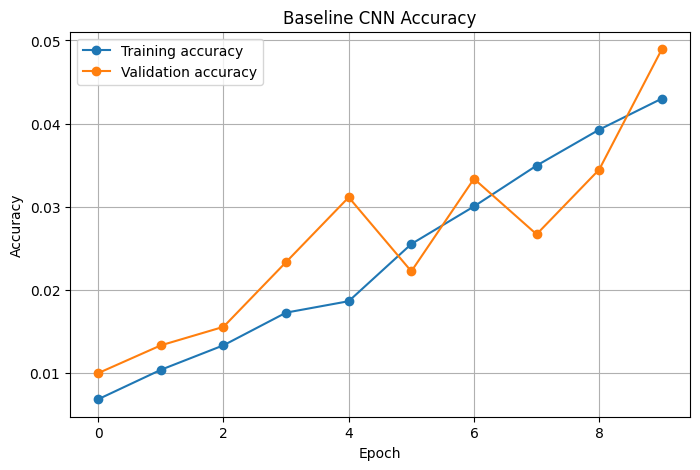

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(history["train_accuracy"], marker="o", label="Training accuracy")
ax.plot(history["val_accuracy"], marker="o", label="Validation accuracy")

ax.set_title("Baseline CNN Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(True)

display(fig)
plt.close(fig)

In [ ]:

import torch
from collections import Counter

checkpoint = torch.load(
    "outputs/baseline/best_model.pth",
    map_location=device,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.tolist())

print("Unique true classes:", len(set(true_labels)))
print("Unique predicted classes:", len(set(predicted_labels)))
print("Most common predictions:", Counter(predicted_labels).most_common(10))


Unique true classes: 200
Unique predicted classes: 121
Most common predictions: [(123, 42), (105, 35), (21, 31), (12, 31), (153, 28), (182, 27), (122, 26), (89, 24), (85, 23), (32, 23)]


In [ ]:

import torch
import torch.nn as nn

model = model.to(device)
model.train()

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

model.zero_grad(set_to_none=True)

outputs = model(images)
loss = nn.CrossEntropyLoss()(outputs, labels)
loss.backward()

print("Batch loss:", round(loss.item(), 4))

for name, parameter in model.named_parameters():
    if parameter.grad is not None:
        print(
            name,
            "| gradient mean:",
            round(parameter.grad.abs().mean().item(), 8)
        )


Batch loss: 4.4856
features.0.weight | gradient mean: 0.02721295
features.0.bias | gradient mean: 0.05644513
features.3.weight | gradient mean: 0.00176583
features.3.bias | gradient mean: 0.00622676
features.6.weight | gradient mean: 0.00036928
features.6.bias | gradient mean: 0.00154654
classifier.1.weight | gradient mean: 0.00261199
classifier.1.bias | gradient mean: 0.00846541


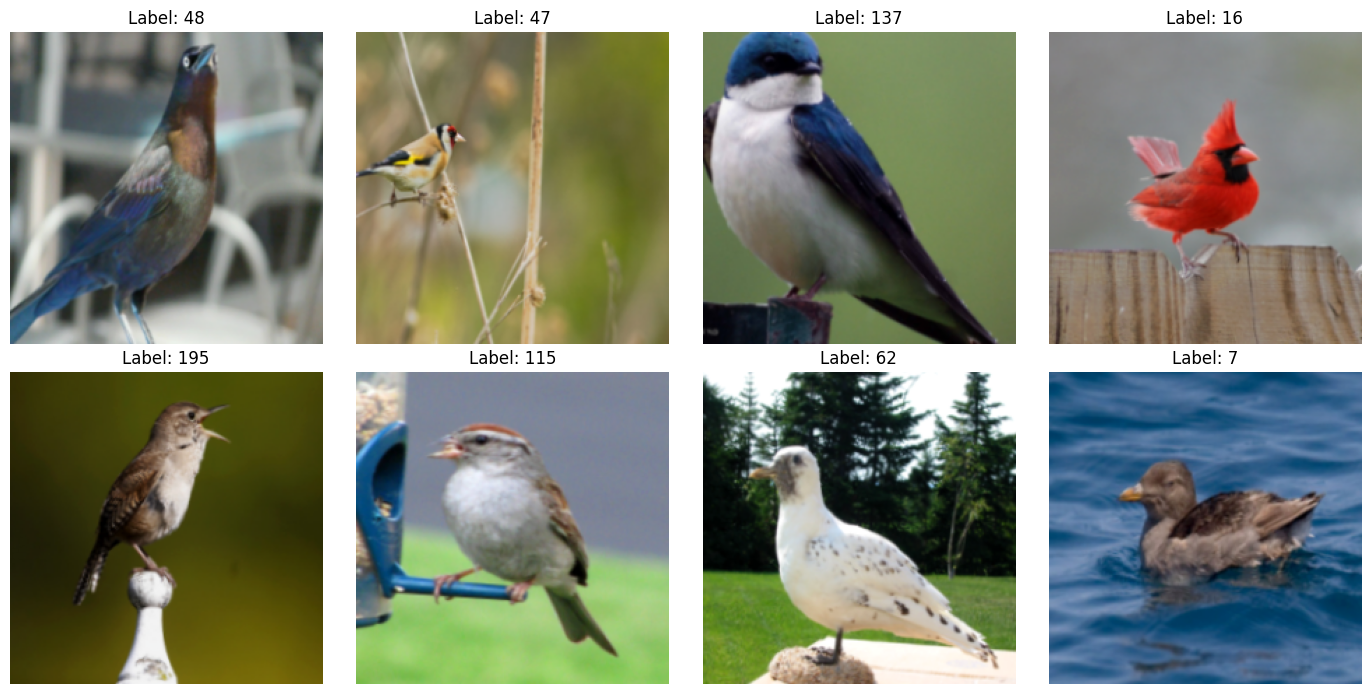

In [ ]:

import matplotlib.pyplot as plt
import torch
from IPython.display import display

images, labels = next(iter(train_loader))

mean = torch.tensor(config["normalization"]["rgb_mean"]).view(3, 1, 1)
std = torch.tensor(config["normalization"]["rgb_std"]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
display(fig)
plt.close(fig)


In [ ]:

import torch
from pathlib import Path
from src.models.baseline_cnn import BaselineCNN
from src.training.train_baseline import train_baseline

checkpoint_path = "outputs/baseline/best_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False,
)

model = BaselineCNN(num_classes=200).to(device)
model.load_state_dict(checkpoint["model_state_dict"])

print("Resuming from epoch:", checkpoint["epoch"])
print("Previous best validation accuracy:",
      f'{checkpoint["best_val_accuracy"]:.2%}')


Resuming from epoch: 10
Previous best validation accuracy: 4.89%


In [ ]:

import copy
from pathlib import Path

import torch
import torch.nn as nn
from torch.optim import Adam
from src.training.train_baseline import run_epoch

# Keep the original experiment untouched.
original_checkpoint = "outputs/baseline/best_model.pth"
extended_checkpoint = "outputs/baseline/extended_best_model.pth"

checkpoint = torch.load(
    original_checkpoint,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])

criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=0.001)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

best_val_accuracy = checkpoint["best_val_accuracy"]
best_state = copy.deepcopy(model.state_dict())

extended_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

for epoch in range(20):
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, device, optimizer
    )
    val_loss, val_acc = run_epoch(
        model, val_loader, criterion, device
    )

    extended_history["train_loss"].append(train_loss)
    extended_history["train_accuracy"].append(train_acc)
    extended_history["val_loss"].append(val_loss)
    extended_history["val_accuracy"].append(val_acc)

    print(
        f"Additional epoch {epoch + 1}/20 | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.2%}",
        flush=True,
    )

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": checkpoint["epoch"] + epoch + 1,
                "model_state_dict": best_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_accuracy": best_val_accuracy,
            },
            extended_checkpoint,
        )

torch.save(
    extended_history,
    "outputs/baseline/extended_training_history.pt",
)

print("\nBest validation accuracy across both runs:",
      f"{best_val_accuracy:.2%}")
print("Extended checkpoint:", extended_checkpoint)


Additional epoch 1/20 | Train loss: 4.6044 | Train accuracy: 4.93% | Val loss: 4.8350 | Val accuracy: 3.78%
Additional epoch 2/20 | Train loss: 4.5473 | Train accuracy: 5.42% | Val loss: 4.8152 | Val accuracy: 3.56%
Additional epoch 3/20 | Train loss: 4.5095 | Train accuracy: 5.54% | Val loss: 4.7631 | Val accuracy: 4.45%
Additional epoch 4/20 | Train loss: 4.4540 | Train accuracy: 6.09% | Val loss: 4.8361 | Val accuracy: 5.23%
Additional epoch 5/20 | Train loss: 4.4129 | Train accuracy: 6.83% | Val loss: 4.7205 | Val accuracy: 5.12%
Additional epoch 6/20 | Train loss: 4.3488 | Train accuracy: 7.05% | Val loss: 4.7306 | Val accuracy: 6.56%
Additional epoch 7/20 | Train loss: 4.3011 | Train accuracy: 7.82% | Val loss: 4.8679 | Val accuracy: 6.45%
Additional epoch 8/20 | Train loss: 4.2519 | Train accuracy: 8.44% | Val loss: 4.8340 | Val accuracy: 6.34%
Additional epoch 9/20 | Train loss: 4.1985 | Train accuracy: 8.72% | Val loss: 4.7881 | Val accuracy: 6.90%
Additional epoch 10/20 | Tra

In [ ]:
import torch
from src.models.baseline_cnn import BaselineCNN

checkpoint = torch.load(
    "outputs/baseline/extended_best_model.pth",
    map_location=device,
    weights_only=False,
)

best_model = BaselineCNN(num_classes=200).to(device)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:",
      f'{checkpoint["best_val_accuracy"]:.2%}')

Best epoch: 30
Best validation accuracy: 10.01%


In [ ]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss()
test_loss = 0.0
test_correct = 0
test_total = 0

best_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        test_loss += loss.item() * batch_size
        test_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        test_total += batch_size

print(f"Test loss: {test_loss / test_total:.4f}")
print(f"Test accuracy: {test_correct / test_total:.2%}")
print(f"Test images evaluated: {test_total}")

Test loss: 4.9442
Test accuracy: 10.01%
Test images evaluated: 5794


In [ ]:

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/baseline")
output_dir.mkdir(parents=True, exist_ok=True)

train_loss_all = history["train_loss"] + extended_history["train_loss"]
val_loss_all = history["val_loss"] + extended_history["val_loss"]
train_acc_all = history["train_accuracy"] + extended_history["train_accuracy"]
val_acc_all = history["val_accuracy"] + extended_history["val_accuracy"]

epochs = range(1, 31)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, train_loss_all, label="Training loss")
axes[0].plot(epochs, val_loss_all, label="Validation loss")
axes[0].set_title("Baseline CNN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, train_acc_all, label="Training accuracy")
axes[1].plot(epochs, val_acc_all, label="Validation accuracy")
axes[1].set_title("Baseline CNN: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(output_dir / "training_curves.png", dpi=160)
plt.show()
plt.close(fig)

print("Saved:", output_dir / "training_curves.png")


Saved: outputs/baseline/training_curves.png


In [ ]:

from pathlib import Path

report = """# Baseline CNN — Person 1

## Objective
Build and evaluate a convolutional neural network from scratch
for classifying bird species in the CUB-200-2011 dataset.

## Dataset
- Training images: 5,092
- Validation images: 899
- Test images: 5,794
- Number of classes: 200
- Input images: RGB, 224 x 224 pixels
- Training preprocessing: light augmentation
- Validation/test preprocessing: deterministic resize and center crop
- Normalization: RGB statistics calculated from the training split

## Model architecture
The model is implemented in `src/models/baseline_cnn.py`.

1. Conv2D: 3 -> 32 channels, 3x3 kernel, ReLU, max pooling
2. Conv2D: 32 -> 64 channels, 3x3 kernel, ReLU, max pooling
3. Conv2D: 64 -> 128 channels, 3x3 kernel, ReLU, max pooling
4. Adaptive average pooling to 1x1
5. Linear classifier: 128 -> 200 class scores

Trainable parameters: 119,048.

The model uses randomly initialized weights; no pretrained model is used.

## Training configuration
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Cross-entropy
- Batch size: 32
- Total epochs: 30
- Model selection: highest validation accuracy
- Random seed: 42

The first experiment trained for 10 epochs. Training then continued
for 20 additional epochs, restoring the saved optimizer state.
The extended experiment used a separate checkpoint.

## Final results

| Metric | Result |
|---|---:|
| Best validation accuracy | 10.01% |
| Test accuracy | 10.01% |
| Test loss | 4.9442 |
| Test images evaluated | 5,794 |

## Interpretation
Training accuracy increased during training, indicating that the
model learned patterns from the training data. However, the final
accuracy remains limited for a 200-class classification problem.
The baseline is a reference point for comparison with other models.

## Limitations
The scratch CNN has limited capacity for distinguishing fine-grained
bird species. Further experiments could investigate architecture,
regularization, learning-rate scheduling, and longer training.
Such experiments should be recorded separately and selected using
validation data, without repeatedly tuning against the test set.

## Artifacts
- Model definition: `src/models/baseline_cnn.py`
- Training script: `src/training/train_baseline.py`
- Best extended checkpoint: `outputs/baseline/extended_best_model.pth`
- Training curves: `outputs/baseline/training_curves.png`
"""

Path("outputs/baseline/README.md").write_text(report, encoding="utf-8")
print("Saved outputs/baseline/README.md")


Saved outputs/baseline/README.md
Saved outputs/baseline/README.md


In [17]:
from pathlib import Path

print("Current directory:", Path.cwd())

for path in [
    "src/models/baseline_cnn.py",
    "src/training/train_baseline.py",
    "outputs/baseline/README.md",
    "outputs/baseline/training_curves.png",
    "outputs/baseline/best_model.pth",
    "outputs/baseline/extended_best_model.pth",
]:
    print(f"{'FOUND' if Path(path).exists() else 'MISSING'}: {path}")

Current directory: /content
MISSING: src/models/baseline_cnn.py
MISSING: src/training/train_baseline.py
MISSING: outputs/baseline/README.md
MISSING: outputs/baseline/training_curves.png
MISSING: outputs/baseline/best_model.pth
MISSING: outputs/baseline/extended_best_model.pth


In [19]:
%cd /content
!git clone -b person1-baseline-cnn https://github.com/TokaElsaayed/Deep-project.git

/content
Cloning into 'Deep-project'...
fatal: Remote branch person1-baseline-cnn not found in upstream origin


In [20]:
%cd /content
!git clone https://github.com/TokaElsaayed/Deep-project.git

/content
Cloning into 'Deep-project'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 49 (delta 3), reused 44 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 7.48 MiB | 8.78 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [21]:
%cd /content/Deep-project
!git switch -c person1-baseline-cnn

/content/Deep-project
Switched to a new branch 'person1-baseline-cnn'


In [22]:
!git branch --show-current
!git status

person1-baseline-cnn
On branch person1-baseline-cnn
nothing to commit, working tree clean


In [25]:
%%writefile /content/Deep-project/src/models/baseline_cnn.py

import torch
import torch.nn as nn


class BaselineCNN(nn.Module):
    """CNN baseline for classifying 200 bird species."""

    def __init__(self, num_classes=200):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

Writing /content/Deep-project/src/models/baseline_cnn.py


In [26]:
%cd /content/Deep-project

from src.models.baseline_cnn import BaselineCNN
import torch

model = BaselineCNN(num_classes=200)
x = torch.randn(2, 3, 224, 224)

print("Output shape:", model(x).shape)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

/content/Deep-project
Output shape: torch.Size([2, 200])
Trainable parameters: 119048


In [27]:

%%writefile /content/Deep-project/src/training/train_baseline.py
import copy
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


def train_baseline(
    model,
    train_loader,
    val_loader,
    device,
    epochs=10,
    learning_rate=0.001,
    checkpoint_path="outputs/baseline/best_model.pth",
):
    set_seed(42)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)

    checkpoint = Path(checkpoint_path)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, device, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_acc:.2%} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_acc:.2%}",
            flush=True,
        )

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_state = copy.deepcopy(model.state_dict())
            torch.save(
                {
                    "epoch": epoch + 1,
                    "model_state_dict": best_state,
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_accuracy": best_accuracy,
                },
                checkpoint,
            )

    torch.save(history, checkpoint.parent / "training_history.pt")
    model.load_state_dict(best_state)

    print(f"Best validation accuracy: {best_accuracy:.2%}")
    print(f"Saved checkpoint: {checkpoint}")

    return model, history


Writing /content/Deep-project/src/training/train_baseline.py


In [28]:
from pathlib import Path

for f in [
    "src/models/baseline_cnn.py",
    "src/training/train_baseline.py",
]:
    print(f, "FOUND" if Path(f).exists() else "MISSING")

src/models/baseline_cnn.py FOUND
src/training/train_baseline.py FOUND


/content/Deep-project


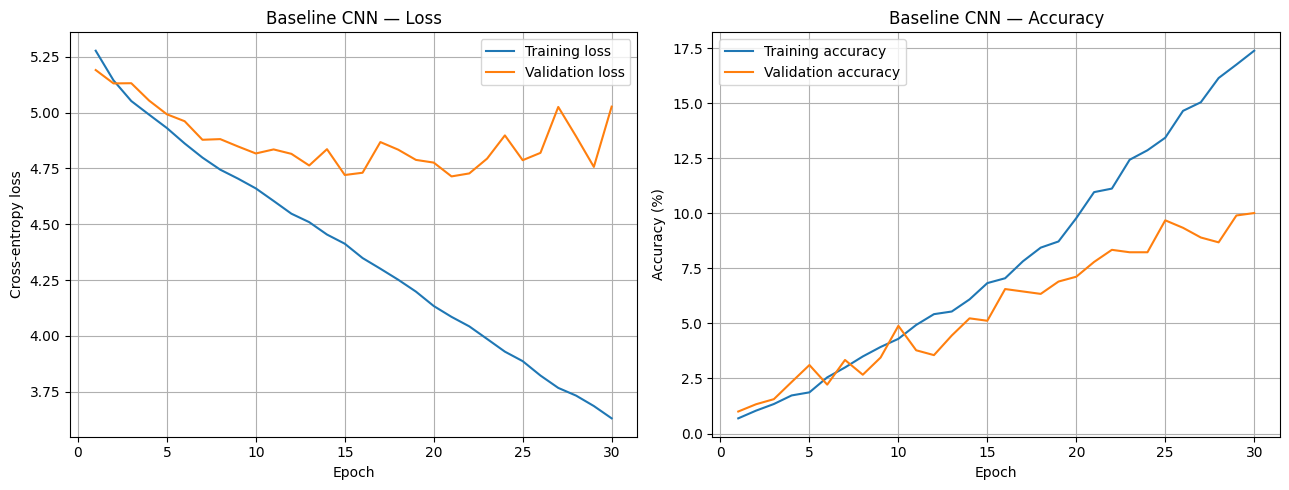

Created: outputs/baseline/README.md
Created: outputs/baseline/training_curves.png
Recorded epochs: 30 30 30 30


In [29]:

%cd /content/Deep-project

from pathlib import Path
import matplotlib.pyplot as plt

out = Path("outputs/baseline")
out.mkdir(parents=True, exist_ok=True)

# Exact metrics recorded in your original notebook: epochs 1–30.
train_loss = [
    5.2768, 5.1443, 5.0516, 4.9907, 4.9308,
    4.8617, 4.7984, 4.7444, 4.7042, 4.6605,
    4.6044, 4.5473, 4.5095, 4.4540, 4.4129,
    4.3488, 4.3011, 4.2519, 4.1985, 4.1341,
    4.0855, 4.0429, 3.9866, 3.9298, 3.8873,
    3.8228, 3.7675, 3.7331, 3.6864, 3.6313
]

train_acc = [
    0.0069, 0.0104, 0.0134, 0.0173, 0.0187,
    0.0255, 0.0300, 0.0350, 0.0393, 0.0430,
    0.0493, 0.0542, 0.0554, 0.0609, 0.0683,
    0.0705, 0.0782, 0.0844, 0.0872, 0.0978,
    0.1096, 0.1112, 0.1243, 0.1286, 0.1343,
    0.1465, 0.1504, 0.1614, 0.1675, 0.1738
]

val_loss = [
    5.1903, 5.1305, 5.1313, 5.0537, 4.9923,
    4.9612, 4.8782, 4.8811, 4.8482, 4.8169,
    4.8350, 4.8152, 4.7631, 4.8361, 4.7205,
    4.7306, 4.8679, 4.8340, 4.7881, 4.7760,
    4.7142, 4.7276, 4.7939, 4.8978, 4.7868,
    4.8196, 5.0251, 4.8936, 4.7567, 5.0265
]

val_acc = [
    0.0100, 0.0133, 0.0156, 0.0234, 0.0311,
    0.0222, 0.0334, 0.0267, 0.0345, 0.0489,
    0.0378, 0.0356, 0.0445, 0.0523, 0.0512,
    0.0656, 0.0645, 0.0634, 0.0690, 0.0712,
    0.0779, 0.0834, 0.0823, 0.0823, 0.0968,
    0.0934, 0.0890, 0.0868, 0.0990, 0.1001
]

# Plot the recorded training history.
epochs = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, train_loss, label="Training loss")
axes[0].plot(epochs, val_loss, label="Validation loss")
axes[0].set_title("Baseline CNN — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, [x * 100 for x in train_acc],
             label="Training accuracy")
axes[1].plot(epochs, [x * 100 for x in val_acc],
             label="Validation accuracy")
axes[1].set_title("Baseline CNN — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(out / "training_curves.png", dpi=160)
plt.show()
plt.close(fig)

# Save the report.
report = """# Baseline CNN — Person 1

## Objective
Build a CNN from scratch to classify 200 bird species.

## Dataset
- Training images: 5,092
- Validation images: 899
- Test images: 5,794
- Classes: 200
- Input: RGB images, 224 x 224 pixels
- Training: light data augmentation
- Validation/test: deterministic preprocessing
- Random seed: 42

## Architecture
1. Conv2D 3 -> 32, 3x3 kernel, ReLU, max pooling
2. Conv2D 32 -> 64, 3x3 kernel, ReLU, max pooling
3. Conv2D 64 -> 128, 3x3 kernel, ReLU, max pooling
4. Adaptive average pooling to 1x1
5. Linear classifier 128 -> 200

Trainable parameters: 119,048.
Weights initialized from scratch; no pretrained model used.

## Training configuration
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Cross-entropy
- Batch size: 32
- Total epochs recorded: 30
- Model selection: highest validation accuracy
- Seed: 42

## Recorded results
- Best validation accuracy: 10.01%
- Test accuracy: 10.01%
- Test loss: 4.9442
- Test images evaluated: 5,794

## Interpretation
The model learned training patterns, but performance remains limited
for fine-grained classification across 200 bird species. This baseline
provides a reference point for comparison with improved models.

## Artifacts
- Model: src/models/baseline_cnn.py
- Training script: src/training/train_baseline.py
- Training curves: outputs/baseline/training_curves.png

Note: The graph was recreated from metrics printed in the original
notebook. Trained checkpoint weights are not included unless recovered
separately from the original runtime or another saved location.
"""

(out / "README.md").write_text(report, encoding="utf-8")

print("Created:", out / "README.md")
print("Created:", out / "training_curves.png")
print("Recorded epochs:", len(train_loss), len(val_loss),
      len(train_acc), len(val_acc))
